# ToF-SIMS depth profiles

Four ways to look at ToF-SIMS depth profiles (sputter profiles):

1. **Total ion count**: ion counts against the sputter time, single and summed ions with a colormap
2. **Normalisation**: counts against the sputter time, raw, normalised to the total ion count and MinMax scaled
3. **SurfaceLab export with separate header**: cleaning of the column names, Matplotlib and Plotly plots, conversion of the fluence into a depth
4. **Comparison of several samples**: one ion ratio of five samples washed at different temperatures

## Import packages

In [1]:
import os

##### Data Management
import pandas as pd

import numpy as np

##### Visualisieren
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import rgb2hex

from sklearn.preprocessing import MinMaxScaler

In [2]:
# importing the own functions from the scientific_utils package
from scientific_utils.general.analysis import Find_First_NaN_Sequence_Start
from scientific_utils.general.analysis import Normalize_Column_To_Reference_Column
from scientific_utils.general.io import Extract_FilePaths
from scientific_utils.general.io import Read_Files_Via_FilePath
from scientific_utils.general.plotting import Convert_cm_To_inch
from scientific_utils.general.plotting import Plotly_Single_Dataframe_Multiple_Columns
from scientific_utils.tof_sims.io import Read_SputterProfile_Files
from scientific_utils.tof_sims.io import Read_SurfaceLab_DepthProfil_Separate_Header
from scientific_utils.tof_sims.plotting import Matplotlib_DepthProfil
from scientific_utils.tof_sims.plotting import Matplotlib_Interactive_SputterProfile_Plot
from scientific_utils.tof_sims.plotting import Matplotlib_SputterProfile_Overview_With_Colormap
from scientific_utils.tof_sims.plotting import Plotly_DepthProfil
from scientific_utils.tof_sims.plotting import Plotly_DepthProfil_Multiple_YAxis

## Create output folders

In [3]:
# create the output folder of it not yet exists
data_outdir = './saved_data/'
if not os.path.exists(data_outdir):
    os.mkdir(data_outdir)

# create the output folder of it not yet exists
images_outdir = './images/'
if not os.path.exists(images_outdir):
    os.mkdir(images_outdir)

## Plot settings

In [4]:
########## Define colours by hex code ##########
yellow = '#ffa200'
orange = '#f97625'
lightpink = '#e94a3a'
pink = '#ce1b49'
lightpurple = '#a90054'
purple = '#7e0059'
darkpurple = '#4c0057'
darkblue = '#0a004d'

########## Colours in a list to access them in a for loop ##########
colors = [yellow, orange, lightpink, pink, lightpurple, purple, darkpurple, darkblue]


########## Colour gradient with the colour package
#beginnig_color = Color("yellow")
#end_color = Color("blue")
#number_of_colorpoints = 4
#color_gradient = list(beginnig_color.range_to(end_color,number_of_colorpoints))
#print(color_gradient)


########## Cologradient with Matplotlib Colormaps
# Available colormaps: https://matplotlib.org/3.1.0/tutorials/colors/colormaps.html#ibm
number_of_colorpoints = 50 # number of colour points taken from the colour gradient with equal distance
colormap = plt.get_cmap('coolwarm', number_of_colorpoints) # Loads a ready-made colormap from Matplotlib
array_of_RGBAcolors = colormap(range(number_of_colorpoints)) # Returns the colormap as RGBA values scaled from 0 to 1
list_of_Hexcolors = [ rgb2hex(array_of_RGBAcolors[i,:]) for i in range(array_of_RGBAcolors.shape[0]) ] # Converts the scaled RGBA values to hex code and puts them in a list

In [5]:
########## Font settings for the PGF file ##########
pgf_with_latex = {                      # setup matplotlib to use latex for output
    "pgf.texsystem": "xelatex",         # change this if using xetex or lautex
    "text.usetex": False,                # use LaTeX to write all text
    #"pgf.rcfonts": False,               # don't setup fonts from rc parameters
    "font.family": "sans-serif",           # standard sans-serif font of Matplotlib
    #"mathtext.fontset": "stixsans",
    "legend.title_fontsize" : 14,
    "legend.fontsize": 10,              # Make the legend/label fonts a little smaller
    "axes.labelsize": 12,               # LaTeX default is 10pt font.
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize" : Convert_cm_To_inch(16, 8),
    'savefig.dpi'         : 300,   ## figure dots per inch or 'figure'
    'savefig.facecolor'   : 'white',    ## figure facecolor when saving
    'savefig.edgecolor'   : 'white',    ## figure edgecolor when saving
    'savefig.format'      : 'png',      ## png, ps, pdf, svg
    'savefig.bbox'        : 'tight', 
    "pgf.preamble": "\n".join([
        r"\usepackage[T1]{fontenc}",    # use utf8 fonts becasue your computer can handle it :)
        r"\usepackage{fontspec}",        # plots will be generated using this preamble
        r"\usepackage{fourier}",
        r"\usepackage{unicode-math}",
        r"\usepackage[basic,italic,symbolgreek,numbers]{mathastext}"
        ])
    }

plt.rcParams.update(pgf_with_latex)

##### one style for all plots: the shared publication style (scientific_utils.general.plotting) replaces the local settings above
from scientific_utils.general.plotting import pgf_with_latex
plt.rcParams.update(pgf_with_latex)

## 1. Total ion count against the sputter time

The single ions and the summed ions (e.g. CoO<sup>-</sup> + CoO<sub>2</sub><sup>-</sup>) are plotted together with the total ion count. The colormap shows which curve belongs to which ion.

In [6]:
#########################################################
##################### Start of the code ##################
#########################################################

########## Path of the folder with the measurement files ##########
path = './data/raw' #The input data is in the folder given by path
print('-------------------')
print('The following Path is selected:', path)
print('-------------------')

-------------------
The following Path is selected: ./data/raw
-------------------


In [7]:
########## Handling of the raw data ##########
#############################################

########## List all files in a directory using scandir() ##########

########## Walking a directory tree and printing the names of the directories and files ########## (only for an overview)
#print('-------------------')
#print('The Following folder and File Structure in the given path is found')
#for foldername, subfolders, filenames in os.walk(path):
#    print(f'Found directory: {foldername}')
#    for file_name in filenames:
#        print(file_name)
#print('-------------------')


########## All files and Directories given as a Dataframe ##########
dataframe_of_allfiles = pd.DataFrame(list(os.walk(path)))  # First column: directory/path ; second column: directories in the given directory/path ; third column: files in the given directory/path
                                              # os.walk('path') returns triples (dirpath, dirnames, files) -> list(os.walk('.')) puts these triples in a list


########## Sort the found files by name ##########
FilterbyName1 = 'NMC_de_TP_neg1sputterprofile with total intensitz.TXT'


print('-------------------')
print('Only Files with the following Name are considered:', FilterbyName1)
print('-------------------')

list_of_filenames = dataframe_of_allfiles[2][0]

########## Sorting the battery files ##########
list_of_Measurements = sorted([k for k in list_of_filenames if FilterbyName1 in k])

########## Filter by the wanted file format ##########
Format = 'TXT'
print('-------------------')
print('Only Files in the Lists with the following Format are considered:', Format)
print('-------------------')

for i in range(len(list_of_Measurements)):
    list_of_Measurements = [i for i in list_of_Measurements if i.endswith(Format)]
print(len(list_of_Measurements))

-------------------
Only Files with the following Name are considered: NMC_de_TP_neg1sputterprofile with total intensitz.TXT
-------------------
-------------------
Only Files in the Lists with the following Format are considered: TXT
-------------------
1


In [8]:
########## Read the files into dataframes ##########

##### read the file
data_complete = []
for i in range(len(list_of_Measurements)):
    count = -1
    with open(os.path.join(path, list_of_Measurements[i]), 'r', encoding='unicode_escape') as infile:
        for line in infile:
            count += 1
            if line.startswith("time"):
                break
    file = pd.read_csv(os.path.join(path, list_of_Measurements[i]), sep='\t', encoding='unicode_escape', skiprows=count, decimal='.', dtype=np.float64)
    data_complete.append(file)
print(data_complete)    

print(data_complete[0].columns[0])

[          time       total       NiO_2-      CoO_2-     BO_2-       BO-  \
0     0.000000    725116.0      84.0094     122.015   14048.8   22927.9   
1     0.265965   1465040.0     203.0660     319.122  114171.0   95620.5   
2     0.531930   1984370.0     324.1510     438.211  181918.0  137215.0   
3     0.797895   2290990.0     419.2710     605.398  220417.0  159335.0   
4     1.063860   2646970.0     705.7280    1016.130  264280.0  186514.0   
..         ...         ...          ...         ...       ...       ...   
371  98.673000  10012300.0  162869.0000  226522.000  326095.0  130280.0   
372  98.939000  10077300.0  164811.0000  229773.000  328317.0  131526.0   
373  99.204900  10141600.0  166709.0000  233135.000  331872.0  131808.0   
374  99.470900  10023500.0  162680.0000  227917.000  325720.0  130189.0   
375  99.736900  10172600.0  166571.0000  234582.000  330039.0  132348.0   

           NiO-        CoO-  Unnamed: 8  Unnamed: 9  
0       326.109     182.031         NaN     

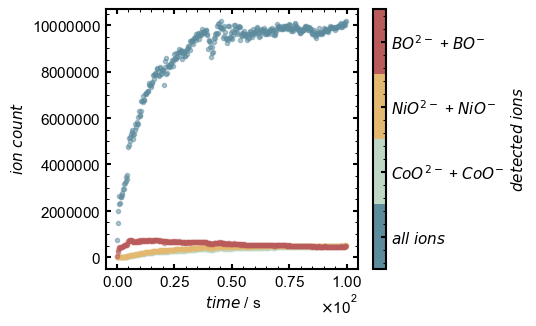

In [9]:
columns_new_dataframe = ['time', 'total', 'CoO- + CoO_2-', 'NiO- + NiO_2-', 'BO- + BO_2-']
dataframe_of_summed_ion_counts = pd.DataFrame(columns=columns_new_dataframe)

dataframe_of_summed_ion_counts['time'] = data_complete[0]['time']
dataframe_of_summed_ion_counts['total'] = data_complete[0]['total']
dataframe_of_summed_ion_counts['CoO- + CoO_2-'] = data_complete[0]['CoO-'] + data_complete[0]['CoO_2-']
dataframe_of_summed_ion_counts['NiO- + NiO_2-'] = data_complete[0]['NiO-'] + data_complete[0]['NiO_2-']
dataframe_of_summed_ion_counts['BO- + BO_2-'] = data_complete[0]['BO-'] + data_complete[0]['BO_2-']





# Plotting of the Charging curves with the above definened function

dataframe = dataframe_of_summed_ion_counts
x_values_column_name = 'time'
y_values_column_names = dataframe_of_summed_ion_counts.columns
lis_of_ticks_label_colormap = [r'$all$ $ions$', r'$CoO^{2-}$ + $CoO^{-}$', r'$NiO^{2-}$ + $NiO^{-}$',r'$BO^{2-}$ + $BO^{-}$']
y_ax_label = r' $ ion$ $count $'
x_ax_label = r' $ time $ / s '
save = 1 
name_figure = 'Sputter_Profile_summed_ions_with_total_ion_count'
legend_title = None # the colour bar shows the ions

Matplotlib_SputterProfile_Overview_With_Colormap(dataframe, x_values_column_name, y_values_column_names, lis_of_ticks_label_colormap, y_ax_label, x_ax_label, save, name_figure, legend_title, y_values_column_names)

## 2. Normalisation of a sputter profile

The counts of single ions depend on the total number of detected ions. To compare the shape of the curves, the counts are normalised to the total ion count and scaled to their maximum, or MinMax scaled.

In [10]:
parameters_ReadSputterProfileFile = {
                                    'path' : './data/raw',
                                    'FileNameFilter' : ['NMC_de_TP'],
                                    'FileFormat' : '.TXT',
                                    'StartStringData' : 'time',
                                    'ColumnSeperationSign' : '\t',
                                    'DecimalSign' : '.'
                                    }

raw_data = Read_SputterProfile_Files(parameters_ReadSputterProfileFile)

-------------------
The following Path is selected: ./data/raw
-------------------
-------------------
Following Files found in the chosen directory: %s ['DP_Anode27_200µm_AppLMIG_Spot04_negative.txt', 'NMC_de_TP_neg1sputterprofile with total intensitz.TXT']
-------------------
[]
Files found: ['NMC_de_TP_neg1sputterprofile with total intensitz.TXT']
-------------------
In total 1 files are selected. 
The name of the files are: 
['NMC_de_TP_neg1sputterprofile with total intensitz.TXT']
-------------------
-------------------
Beginning reading at the String: time
Column Separation sign: 	
Decimal Sign: .
-------------------
------------------------------------------
reading files beginning at row 1
reading file 1 complete
------------------------------------------


In [11]:
#print(raw_data[0])

for i in range(len(raw_data[0].columns)):
    print('Column %s: --> %s' %(i, raw_data[0].columns[i]))

Column 0: --> time
Column 1: --> total
Column 2: --> NiO_2-
Column 3: --> CoO_2-
Column 4: --> BO_2-
Column 5: --> BO-
Column 6: --> NiO-
Column 7: --> CoO-
Column 8: --> Unnamed: 8
Column 9: --> Unnamed: 9


In [12]:
# smaller figures for the sputter profiles
# plt.rcParams.update({"figure.figsize" : Convert_cm_To_inch(1*10, 1*8)})   # size from the shared publication style (one style for all plots)

### Raw counts

The Dataframe with the variable name raw_data is used.
The option to change the name of the variable dynamically is missing here!
---------------------------
There are 1 different dataframes in the loaded data list
---------------------------
Index(['time', 'total', 'NiO_2-', 'CoO_2-', 'BO_2-', 'BO-', 'NiO-', 'CoO-',
       'Unnamed: 8', 'Unnamed: 9'],
      dtype='object')
-------------------
Creating 1 plots
-------------------
-------------------
The following X-Axis for the 1 differnt plots are selected: ['time']
-------------------
-------------------
Y-Axis for the 1 plot are: ['total', 'NiO_2-', 'BO-']
-------------------
-------------------
The following X-Axis for the 1 differnt plots are selected: ['$time$ / s']
-------------------
-------------------
The following Y-Axis for the 1 differnt plots are selected: ['$Counts$']
-------------------
-------------------
Axis Style for the 1 plot are: [(-4, 4), (None, None), 'No', array([   0,  500, 1000, 1500]), (None, None), 'No', a

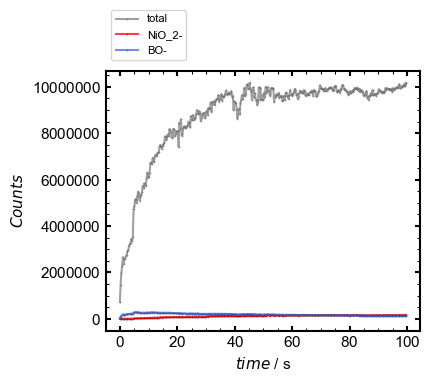

In [13]:
input_parameters_Plot = {
    'number_of_plots': '1',
    'list_of_x_axis_names': ['time'],
    'list_of_list_with_y_axis_names': [['total', 'NiO_2-', 'BO-']],
    #'list_of_list_with_y_axis_names': [['total']],
    'list_of_list_with_y_curve_labels': [[r'Sputter Profile Cathode']],
    'list_of_x_axis_labels' : [r'$time$ / s'],
    'list_of_y_axis_labels' : [r'$Counts$'],
    'list_of_list_of_axis_style_options' : [[(-4,4), (None, None), 'No', np.arange(0, 1550, 500), (None, None), 'No', np.arange(278, 299, 2)]], # # in the form ['power Limits (-4,4)', 'Y-Lim (None, None)', Y-Ticks Enable 'Yes','Y-Ticks list(100, 1000, 10000)', 'X-Lim (None, None)', X-Ticks Enable 'Yes','X-Ticks list(100, 1000, 10000)']
    'list_of_list_of_list_with_y_curve_style' : [[['grey', 0.75, '.', 2.0,'-', 1.5], ['red', 0.75, '.', 2.0,'-', 1.5], ['royalblue', 0.75, '.', 2.0,'-', 1.5]]],
    'list_of_list_of_list_with_y_curve_style_area_filling_options' : [[[False], [False], [False]]], # in the form [If Area should be filled with color True or False, between which curce given by index, Color, Transperancy] --> Example: [True, 1, 'orange', 0.5]
    'list_of_list_with_colorbar_options' : [[False]], 
    'list_of_list_for_saving_options' : [[True, '00_Sputter_Profil']],                      #[Saving first Plot True or False, First_Plot_Name, Saving second Plot True or False, ......]
    'list_of_list_for_vlines_and_text' : []
    }
list_of_dataframes = [raw_data[0]]
Matplotlib_Interactive_SputterProfile_Plot(list_of_dataframes, input_parameters_Plot)

### Normalised to the total ion count and scaled to the maximum

In [14]:
raw_data[0]['BO-_normalized_to_total'] = raw_data[0]['BO-'] / raw_data[0]['total']
raw_data[0]['NiO_2-_normalized_to_total'] = raw_data[0]['NiO_2-'] / raw_data[0]['total']
#print(raw_data[0])

In [15]:
raw_data[0]['BO-_normalized_to_total_and_scaled'] = raw_data[0]['BO-_normalized_to_total'] / raw_data[0]['BO-_normalized_to_total'].max()
raw_data[0]['NiO_2-_normalized_to_total_and_scaled'] = raw_data[0]['NiO_2-_normalized_to_total'] / raw_data[0]['NiO_2-_normalized_to_total'].max()
#print(raw_data[0])

The Dataframe with the variable name raw_data is used.
The option to change the name of the variable dynamically is missing here!
---------------------------
There are 1 different dataframes in the loaded data list
---------------------------
Index(['time', 'total', 'NiO_2-', 'CoO_2-', 'BO_2-', 'BO-', 'NiO-', 'CoO-',
       'Unnamed: 8', 'Unnamed: 9', 'BO-_normalized_to_total',
       'NiO_2-_normalized_to_total', 'BO-_normalized_to_total_and_scaled',
       'NiO_2-_normalized_to_total_and_scaled'],
      dtype='object')
-------------------
Creating 1 plots
-------------------
-------------------
The following X-Axis for the 1 differnt plots are selected: ['time']
-------------------
-------------------
Y-Axis for the 1 plot are: ['NiO_2-_normalized_to_total_and_scaled', 'BO-_normalized_to_total_and_scaled']
-------------------
-------------------
The following X-Axis for the 1 differnt plots are selected: ['$time$ / s']
-------------------
-------------------
The following Y-Axis for 

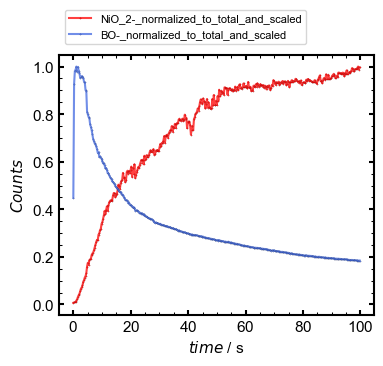

In [16]:
input_parameters_Plot = {
    'number_of_plots': '1',
    'list_of_x_axis_names': ['time'],
    'list_of_list_with_y_axis_names': [['NiO_2-_normalized_to_total_and_scaled', 'BO-_normalized_to_total_and_scaled']],
    'list_of_list_with_y_curve_labels': [[r'Sputter Profile Cathode']],
    'list_of_x_axis_labels' : [r'$time$ / s'],
    'list_of_y_axis_labels' : [r'$Counts$'],
    'list_of_list_of_axis_style_options' : [[(-4,4), (None, None), 'No', np.arange(0, 1550, 500), (None, None), 'No', np.arange(278, 299, 2)]], # # in the form ['power Limits (-4,4)', 'Y-Lim (None, None)', Y-Ticks Enable 'Yes','Y-Ticks list(100, 1000, 10000)', 'X-Lim (None, None)', X-Ticks Enable 'Yes','X-Ticks list(100, 1000, 10000)']
    'list_of_list_of_list_with_y_curve_style' : [[['red', 0.75, '.', 2.0,'-', 1.5], ['royalblue', 0.75, '.', 2.0,'-', 1.5]]],
    'list_of_list_of_list_with_y_curve_style_area_filling_options' : [[[False], [False]]], # in the form [If Area should be filled with color True or False, between which curce given by index, Color, Transperancy] --> Example: [True, 1, 'orange', 0.5]
    'list_of_list_with_colorbar_options' : [[False]], 
    'list_of_list_for_saving_options' : [[True, '00_Sputter_Profil_Normalized_to_total_and_scaled']],                      #[Saving first Plot True or False, First_Plot_Name, Saving second Plot True or False, ......]
    'list_of_list_for_vlines_and_text' : []
    }
list_of_dataframes = [raw_data[0]]
Matplotlib_Interactive_SputterProfile_Plot(list_of_dataframes, input_parameters_Plot)

### MinMax scaling (scikit-learn)

In [17]:
scaler = MinMaxScaler()

In [18]:
# raw_data[0]['BO-_minmaxscaled'] = scaler.fit_transform(raw_data[0]['BO-'])
# raw_data[0]['NiO_2-_minmaxscaled'] = scaler.fit_transform(raw_data[0]['NiO_2-'])
# raw_data[0]['total_minmaxscaled'] = scaler.fit_transform(raw_data[0]['total'])
#print(raw_data[0])
#

raw_data[0][['NiO-_minmaxscaled', 'CoO-_minmaxscaled', 'BO-_minmaxscaled']] = scaler.fit_transform(raw_data[0][['NiO-', 'CoO-', 'BO-']])

The Dataframe with the variable name raw_data is used.
The option to change the name of the variable dynamically is missing here!
---------------------------
There are 1 different dataframes in the loaded data list
---------------------------
Index(['time', 'total', 'NiO_2-', 'CoO_2-', 'BO_2-', 'BO-', 'NiO-', 'CoO-',
       'Unnamed: 8', 'Unnamed: 9', 'BO-_normalized_to_total',
       'NiO_2-_normalized_to_total', 'BO-_normalized_to_total_and_scaled',
       'NiO_2-_normalized_to_total_and_scaled', 'NiO-_minmaxscaled',
       'CoO-_minmaxscaled', 'BO-_minmaxscaled'],
      dtype='object')
-------------------
Creating 1 plots
-------------------
-------------------
The following X-Axis for the 1 differnt plots are selected: ['time']
-------------------
-------------------
Y-Axis for the 1 plot are: ['NiO-_minmaxscaled', 'CoO-_minmaxscaled', 'BO-_minmaxscaled']
-------------------
-------------------
The following X-Axis for the 1 differnt plots are selected: ['$time$ / s']
-------------

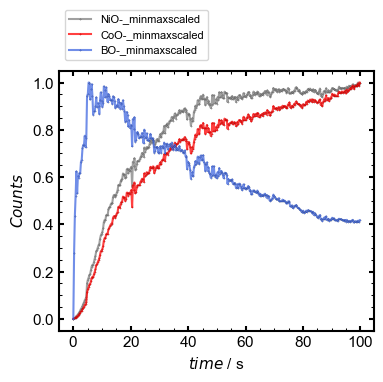

In [19]:
input_parameters_Plot = {
    'number_of_plots': '1',
    'list_of_x_axis_names': ['time'],
    'list_of_list_with_y_axis_names': [['NiO-_minmaxscaled', 'CoO-_minmaxscaled', 'BO-_minmaxscaled']],
    'list_of_list_with_y_curve_labels': [[r'Sputter Profile Cathode']],
    'list_of_x_axis_labels' : [r'$time$ / s'],
    'list_of_y_axis_labels' : [r'$Counts$'],
    'list_of_list_of_axis_style_options' : [[(-4,4), (None, None), 'No', np.arange(0, 1550, 500), (None, None), 'No', np.arange(278, 299, 2)]], # # in the form ['power Limits (-4,4)', 'Y-Lim (None, None)', Y-Ticks Enable 'Yes','Y-Ticks list(100, 1000, 10000)', 'X-Lim (None, None)', X-Ticks Enable 'Yes','X-Ticks list(100, 1000, 10000)']
    'list_of_list_of_list_with_y_curve_style' : [[['grey', 0.75, '.', 2.0,'-', 1.5], ['red', 0.75, '.', 2.0,'-', 1.5], ['royalblue', 0.75, '.', 2.0,'-', 1.5]]],
    'list_of_list_of_list_with_y_curve_style_area_filling_options' : [[[False], [False], [False]]], # in the form [If Area should be filled with color True or False, between which curce given by index, Color, Transperancy] --> Example: [True, 1, 'orange', 0.5]
    'list_of_list_with_colorbar_options' : [[False]], 
    'list_of_list_for_saving_options' : [[True, '00_Sputter_Profil_Oxides_minmaxscaled']],                      #[Saving first Plot True or False, First_Plot_Name, Saving second Plot True or False, ......]
    'list_of_list_for_vlines_and_text' : []
    }

list_of_dataframes = [raw_data[0]]
Matplotlib_Interactive_SputterProfile_Plot(list_of_dataframes, input_parameters_Plot)

In [20]:
# back to the default figure size
plt.rcParams.update(pgf_with_latex)

## 3. SurfaceLab depth profile with separate header

SurfaceLab writes the peak labels and the m/z values in two header rows. Columns without data are removed and columns without a label get a unique name.

In [21]:
a = path = './data/raw'
b = FilterByNameList = ['DP_Anode']
c = FileFormat = '.txt'
d = seperation_of_the_values = '\t'

depth_profils, file_names, column_names, column_names2 = Read_SurfaceLab_DepthProfil_Separate_Header(a, b, c , d)

-------------------
Following Files found in the chosen directory: %s ['DP_Anode27_200µm_AppLMIG_Spot04_negative.txt', 'NMC_de_TP_neg1sputterprofile with total intensitz.TXT']
-------------------
[]
Files found: ['DP_Anode27_200µm_AppLMIG_Spot04_negative.txt']
-------------------
In total 1 files are selected. 
The name of the files are: 
['DP_Anode27_200µm_AppLMIG_Spot04_negative.txt']
-------------------
['6,55656e+16', '1,29383e+06', '50061,2', '2559,69', '390,778', '915,426', '9858,39', '25941,3', '1862,27', '399,426', '22044,3', '236201', '415766', '98,031', '60,0105', '3586,5', '6086,81', '17,0008', '195,099', '333,286', '355,329', '382,36', '8925,21', '24129,5', '46,0067']


In [22]:
print('extracted', len(column_names), 'columns with Assigned label \nAND', len(column_names2), 'column names with a m/z value')
print('| \n|')

print('rename the first two column names into Fluence and total counts')
column_names[0] = 'Fluence / ions/cm^2'
column_names[1] = 'total counts'

column_names2[0] = 'Fluence / ions/cm^2'
column_names2[1] = 'total counts'
print('| \n|')


# Define the substring to search for
substring = ''

print('delete all column names with match exactly the substring: ', substring)

# Find all indices of elements containing the substring
indices_to_remove = [i for i, item in enumerate(column_names2) if substring == item]

# Remove elements based on the indices
column_names2_cleaned = [item for i, item in enumerate(column_names2) if i not in indices_to_remove]
column_names_cleaned = [item for i, item in enumerate(column_names) if i not in indices_to_remove]
print('| \n|')
print('only', len(column_names_cleaned), 'columns with Assigned label \nAND', len(column_names2_cleaned), 'column names with a m/z value are left over')
print('| \n|')
print('finished :)')

extracted 25 columns with Assigned label 
AND 25 column names with a m/z value
| 
|
rename the first two column names into Fluence and total counts
| 
|
delete all column names with match exactly the substring:  
| 
|
only 25 columns with Assigned label 
AND 25 column names with a m/z value are left over
| 
|
finished :)


In [23]:
print('Rename all columns which have not jet a label assigned')
print('| \n|')

# Initialize a set to track seen names and a dictionary for counters
seen_names = set()
unique_columns = []

for col in column_names_cleaned:
    # If the column name is empty or a duplicate
    if not col or col in seen_names:
        # Generate a new unique name
        count = 1
        new_col = f"Unnamed_{count}"
        while new_col in seen_names:
            count += 1
            new_col = f"Unnamed_{count}"
        unique_columns.append(new_col)
        print('New column name added:', new_col)
        seen_names.add(new_col)
    else:
        # Otherwise, keep the column name and add to seen_names
        unique_columns.append(col)
        seen_names.add(col)
print('| \n|')
print('finished :)')

Rename all columns which have not jet a label assigned
| 
|
| 
|
finished :)


In [24]:
print('Delete all entries in the dataframe where all values in a column are empty')
print('| \n|')
# Remove columns that only contain empty strings
depth_profils_cleaned = depth_profils[0].loc[:, ~(depth_profils[0] == '').all()]
print('finished :)')
print('| \n|')

Delete all entries in the dataframe where all values in a column are empty
| 
|
finished :)
| 
|


In [25]:
print('Add', len(unique_columns), 'column names to the dataframe with', len(depth_profils_cleaned.columns), 'columns')
print('| \n|')

if len(unique_columns) == len(depth_profils_cleaned.columns):
   depth_profils_cleaned.columns = unique_columns
else:
    print('Error: Number of column names could not match to the number of columns in the dataframe.')
    
print('finished :)')

Add 25 column names to the dataframe with 25 columns
| 
|
finished :)


In [26]:
for i in range(len(depth_profils_cleaned.columns)):
    print('Index:', i, 'Column Name:', depth_profils_cleaned.columns[i])

Index: 0 Column Name: Fluence / ions/cm^2
Index: 1 Column Name: total counts
Index: 2 Column Name: ZnO-
Index: 3 Column Name: Zn_2O-
Index: 4 Column Name: ZnH-
Index: 5 Column Name: InH-
Index: 6 Column Name: C_2H-
Index: 7 Column Name: H-
Index: 8 Column Name: InO-
Index: 9 Column Name: AlO-
Index: 10 Column Name: ZnO_2-
Index: 11 Column Name: OH-
Index: 12 Column Name: O-
Index: 13 Column Name: Zn_4-
Index: 14 Column Name: CZn-
Index: 15 Column Name: PbO-
Index: 16 Column Name: PbO_2-
Index: 17 Column Name: KO-
Index: 18 Column Name: Zn_3O-
Index: 19 Column Name: Zn_3OH_2-
Index: 20 Column Name: AlO_2-
Index: 21 Column Name: ^68ZnOH_3-
Index: 22 Column Name: ^68ZnOH-
Index: 23 Column Name: ZnOH-
Index: 24 Column Name: TiO-


### Plot data

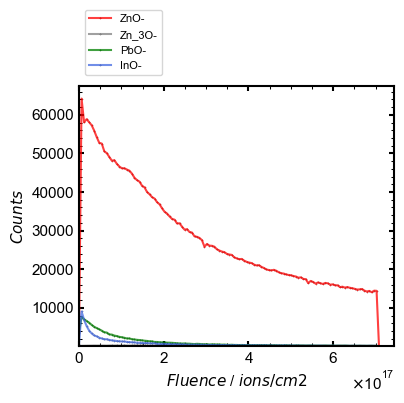

In [27]:
a = depth_profils_cleaned
b = 'Fluence / ions/cm^2'
c = ['ZnO-', 'Zn_3O-', 'PbO-', 'InO-']
d = ['red', 'grey', 'green', 'royalblue']
e = (10, None)
f = (1e2, None)
g = 'linear'
h = r'$Fluence$ / $ions/cm2$'
i = r'$Counts$'
j = images_outdir + file_names[0] + '.png'

Matplotlib_DepthProfil(a, b, c, d, e, f, g,  h, i, j)

In [28]:
a = Dataframe = depth_profils_cleaned
b = x_column_name = 'Fluence / ions/cm^2'
c = list_of_y_column_names = ['ZnO-', 'Zn_3O-', 'PbO-', 'InO-']
d = list_of_curve_label = ['ZnO-', 'Zn_3O-', 'PbO-', 'InO-']
e = list_of_colors = ['red', 'grey', 'green', 'royalblue']
f = XAxis_Label = '<i> Fluence </i> / <sup>ions</sup>/<sub>cm<sup>2</sup></sub>'
g = YAxis_Label = '<i> Counts </i>'
h = Filepath_for_saving = images_outdir + file_names[0] + '.html'

Plotly_DepthProfil(a, b, c , d, e, f, g, h)

### Normalisation to the total counts

In [29]:
## Normalize to the total counts
# copy the dataframe
depth_profils_normalized = depth_profils_cleaned.copy()

#Normalise the dataframe to the total counts
a = dataframe = depth_profils_normalized
for i in dataframe.columns.tolist():
    b = column_name1 = i
    c = column_name2 = 'total counts'

    Normalize_Column_To_Reference_Column(a, b, c)

In [30]:
a = Dataframe = depth_profils_normalized
b = x_column_name = 'Fluence / ions/cm^2'
c = list_of_y_column_names = ['ZnO-_normalized_to_total counts', 'Zn_3O-_normalized_to_total counts', 'PbO-_normalized_to_total counts', 'InO-_normalized_to_total counts']
d = list_of_curve_label = ['ZnO- / total counts', 'Zn_3O- / total counts', 'PbO- / total counts', 'InO- / total counts']
e = list_of_colors = ['red', 'grey', 'green', 'royalblue']
f = XAxis_Label = '<i> Fluence </i> / <sup>ions</sup>/<sub>cm<sup>2</sup></sub>'
g = YAxis_Label = '<i> Counts </i>'
h = Filepath_for_saving = images_outdir + file_names[0] + '.html'

Plotly_DepthProfil_Multiple_YAxis(a, b, c , d, e, f, g, h)

### Conversion of the fluence into a depth

In [31]:
print('Previous First 4 Columns:' + str(depth_profils_normalized.columns[:4]))
print('| \n|')
print('Adding Depth Column to Dataframe:')
print('| \n|')
sputter_yield = 2.0760019*10**21 # ions/cm^3 # Determined via NCM Pellet and LMIG 30 kV in Long Pulses for Orbitrap Depth Profiles
depth = (depth_profils_normalized[depth_profils_normalized.columns[0]] / sputter_yield) * 10**7

depth_profils_normalized.insert(1, 'Depth / nm', depth)

print('After Adding the Depth Column:' + str(depth_profils_normalized.columns[:5]))
print('| \n|')
print('finished :)')

Previous First 4 Columns:Index(['Fluence / ions/cm^2', 'total counts', 'ZnO-', 'Zn_2O-'], dtype='object')
| 
|
Adding Depth Column to Dataframe:
| 
|
After Adding the Depth Column:Index(['Fluence / ions/cm^2', 'Depth / nm', 'total counts', 'ZnO-', 'Zn_2O-'], dtype='object')
| 
|
finished :)


In [32]:
print('Exporting Data to txt file .....')
depth_profils_normalized.to_csv(data_outdir + 'Exported_' + file_names[0], sep='\t', index=False)
print('| \n|')
print('finished :)')

Exporting Data to txt file .....
| 
|
finished :)


## 4. Comparison of several samples

NiO<sub>2</sub><sup>2</sup>H<sup>-</sup> normalised to NiO<sub>2</sub><sup>-</sup> for single crystal NCM washed overnight at different temperatures. Every curve is shifted so that its last data point is zero.

In [33]:
path_comparison = './data/raw/washing-temperature'

# one file per sample, in the same order as the sample names below
list_of_filter_strings = ['20241106', '20241203', '20240808', '20240725', '20240724']

In [34]:
list_of_file_paths = []

for i in list_of_filter_strings:
    a = path_for_searching = path_comparison
    b = filter_string = i
    c = file_format = '.txt'

    file_path = Extract_FilePaths(a, b, c)

    list_of_file_paths.append(file_path[0])

Path for searching:  ./data/raw/washing-temperature
Found File!
Path for searching:  ./data/raw/washing-temperature
Found File!
Path for searching:  ./data/raw/washing-temperature
Found File!
Path for searching:  ./data/raw/washing-temperature
Found File!
Path for searching:  ./data/raw/washing-temperature
Found File!


In [35]:
a = list_of_file_paths = list_of_file_paths
b = StartString_of_the_wanted_Row = 'Fluence'
c = seperation_of_the_values = '\t'
d = decimal_sign = '.'

data, filenames = Read_Files_Via_FilePath(a, b, c, d)

-------------------
The following Path is selected:
./data/raw/washing-temperature\Exported_01_20241106_scNCM_washedovernight_90C_AIIS_Discard.txt
./data/raw/washing-temperature\Exported_01_20241203_scNCM_washedovernight_90C_AIIS_Discard.txt
./data/raw/washing-temperature\Exported_20240808_scNCM_OverNightWashedAt70Grad_Cryo_Spot01.txt
./data/raw/washing-temperature\Exported_20240725_scNCM_OverNightWashedAt50Grad_Cryo_-70_Spot01.txt
./data/raw/washing-temperature\Exported_20240724_scNCM_OverNightWashed_Cryo_-70Grad_Spot01.txt
-------------------
Beginning reading at the String: Fluence
Column Separation sign: 	
Decimal Sign: .
-------------------
------------------------------------------
reading files beginning at row 0
reading file 1 complete
------------------------------------------
Extracted Filename: washing-temperature\Exported_01_20241106_scNCM_washedovernight_90C_AIIS_Discard
------------------------------------------
reading files beginning at row 0
reading file 2 complete
---

In [36]:
list_subdataframes = []
column_name = 'NiO_2^2H-_normalized_to_NiO_2-'
sample_index = ['_90Grad_First_Time', '_90Grad_Second_Time', '_70Grad', '_50Grad', '_RT']

for i in range(len(data)):
    dataframe = data[i]
    fluence = 'Fluence / ions/cm^2'
    depth = 'Depth / nm'
    subdataframe = dataframe[[fluence, depth, column_name]]
    subdataframe.columns = [fluence + sample_index[i], depth + sample_index[i], column_name + sample_index[i]]

    list_subdataframes.append(subdataframe)

small_data = pd.concat(list_subdataframes, axis=1)

In [37]:
# normalise to the last data point of every column
for i in [small_data.columns[2], small_data.columns[5], small_data.columns[8], small_data.columns[11], small_data.columns[14]]:
    result_index = Find_First_NaN_Sequence_Start(small_data, i)-1
    small_data[i] = small_data[i]-small_data[i].iloc[result_index]

# # normalise to the first data point of every column
# for i in [small_data.columns[1], small_data.columns[3], small_data.columns[5], small_data.columns[7], small_data.columns[9]]:
#     small_data[i] = small_data[i]/small_data[i].iloc[0]

In [38]:
a = dataframe = small_data
b = list_of_x_column_names = [small_data.columns[1], small_data.columns[4], small_data.columns[7], small_data.columns[10], small_data.columns[13]]
c = list_of_y_column_names = [small_data.columns[2], small_data.columns[5], small_data.columns[8], small_data.columns[11], small_data.columns[14]]
d = list_of_curve_label = ['90 °C, 1st', '90 °C, 2nd', '70 °C', '50 °C', 'RT'] # washing temperature (same order as sample_index)
e = list_of_color = ['blue', 'orange', 'green', 'red', 'grey']
f = XAxis_Label = '<i> Depth </i> / nm'
g = YAxis_Label = '<i> Counts normalized to NiO<sub>2</sub><sup>-</sup> </i>'
h = Filepath_for_saving = images_outdir + 'NiO_2^2H-_DepthXAxis' + '.html'

Plotly_Single_Dataframe_Multiple_Columns(a, b, c, d, e, f, g, h)

In [39]:
print('Exporting Data to txt file .....')
small_data.to_csv(data_outdir + 'Exported_' + 'Washing Temp'+ '.txt', sep='\t', index=False)
print('| \n|')
print('finished :)')

Exporting Data to txt file .....
| 
|
finished :)
